# BTP-1: numbered GPU experiment
Run cells in order. This trains the proposed **96 x 96 x 96, width-16** model on all 369 labelled BraTS 2020 patients with separate training, validation and test partitions.

Before starting: upload `btp1_gpu_code.zip` to Google Drive in `MyDrive/BTP1_GPU/`. Open this notebook in Google Colab and select a GPU runtime. The download uses the existing project's Kaggle mirror helper; comply with the dataset's access terms. You can instead use your existing BraTS data as described in Step 4.

Steps 1–10 are the main experiment. Steps 11–12 are additional experiments. Step 13 checks and downloads the results. Stop and inspect any failed cell before continuing. No GPU training has been run by creating this notebook.

## 1. Confirm GPU

In [ ]:
import sys, subprocess, shutil, json, os, time
from pathlib import Path
import torch
subprocess.run(['nvidia-smi'], check=True)
assert torch.cuda.is_available(), 'Select a GPU runtime, then rerun this cell.'
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__, '| CUDA:', torch.version.cuda)


GPU: Tesla T4
PyTorch: 2.11.0+cu130 | CUDA: 13.0


## 2. Mount Drive and unpack the code
The ZIP is small and contains source code and labels, not MRI volumes. Outputs are saved to Drive; MRI and cached tensors stay on the runtime disk for faster access.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import zipfile
DRIVE = Path('/content/drive/MyDrive/BTP1_GPU')
BUNDLE = DRIVE / 'btp1_gpu_code.zip'
assert BUNDLE.is_file(), f'Upload the code ZIP here first: {BUNDLE}'
PROJECT = Path('/content/BTP1_GPU')
PROJECT.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(BUNDLE) as z:
    z.extractall(PROJECT)
os.chdir(PROJECT)
ARTIFACTS = DRIVE / 'runs' / 'roi96_seed42'
ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path('/content/brats2020_training')
MAPPING = PROJECT / 'labels' / 'name_mapping.csv'
CACHE = Path('/content/roi96_cache')
RUN = ARTIFACTS / 'fixed_split'


Mounted at /content/drive


## 3. Install dependencies and record the environment

In [ ]:
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(PROJECT), 'kagglehub'], check=True)
def run(*args):
    command = [sys.executable, '-u', *map(str, args)]
    print('Running:', ' '.join(command), flush=True)
    started = time.monotonic()
    subprocess.run(command, check=True)
    print(f'Finished in {(time.monotonic()-started)/60:.1f} minutes', flush=True)
environment = subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True)
(ARTIFACTS / 'environment.txt').write_text(environment)
shutil.copy2(BUNDLE, ARTIFACTS / 'source_code.zip')
(ARTIFACTS / 'gpu.txt').write_text(subprocess.check_output(['nvidia-smi'], text=True))
import pandas as pd


In [ ]:


def run(*args):
    command = [sys.executable, "-u", *map(str, args)]

    with subprocess.Popen(
        command,
        cwd=PROJECT,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)

        returncode = process.wait()

    if returncode:
        raise RuntimeError(
            f"Command failed ({returncode}). See the error printed above."
        )

In [ ]:
print("Starting dataset download...", flush=True)

run(
    "scripts/download_brats2020.py",
    "--mapping-csv", MAPPING,
    "--output-dir", DATA_ROOT,
    "--workers", 4,
)

Starting dataset download...

BraTS files:   0%|          | 0/1845 [00:00<?, ?it/s]Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.

BraTS files:   0%|          | 1/1845 [00:01<55:09,  1.79s/it]Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.
Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.

BraTS files:   0%|          | 3/1845 [00:02<20:30,  1.50it/s]Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.

BraTS files:   0%|          | 4/1845 [00:02<14:48,  2.07it/s]Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.

BraTS files:   0%|          | 5/1845 [00:02<13:44,  2.23it/s]Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.

BraTS files:   0%|          | 6/1845 [00:03<11:00,  2.79it/s]Downloading to /content/brats2020_training/BraTS2020_TrainingData/M

RuntimeError: Command failed (1). See the error printed above.

In [7]:
import os
os.environ["DISABLE_COLAB_CACHE"] = "true"

run(
    "scripts/download_brats2020.py",
    "--mapping-csv", MAPPING,
    "--output-dir", DATA_ROOT,
    "--workers", 2,
)


BraTS files: 0it [00:00, ?it/s]
BraTS files: 0it [00:00, ?it/s]


## 4. Obtain the real dataset
Default: download the 1,845 training NIfTI files using the supplied helper and the 369-patient grade mapping. The uncompressed cohort is about 30.83 GiB; allow extra disk space for the download and processed caches. This is the network-dependent part. If Kaggle requests authorization, complete its normal sign-in/access steps before retrying; the helper cannot grant access.

**Alternative:** upload/extract your existing `data/raw` cohort into the Colab runtime, set `DATA_ROOT` to that directory, and skip the download command below. Use the original four modalities and segmentation masks, not the existing 32-cubed caches. The helper handles the mirror's special segmentation filename for patient 355.

In [ ]:
print('Local free disk GiB:', round(shutil.disk_usage('/content').free / 2**30, 1))
assert len(pd.read_csv(MAPPING)) == 369
run('scripts/download_brats2020.py', '--mapping-csv', MAPPING,
    '--output-dir', DATA_ROOT, '--workers', 4)


Local free disk GiB: 70.1
Running: /usr/bin/python3 -u scripts/download_brats2020.py --mapping-csv /content/BTP1_GPU/labels/name_mapping.csv --output-dir /content/brats2020_training --workers 4


CalledProcessError: Command '['/usr/bin/python3', '-u', 'scripts/download_brats2020.py', '--mapping-csv', '/content/BTP1_GPU/labels/name_mapping.csv', '--output-dir', '/content/brats2020_training', '--workers', '4']' returned non-zero exit status 1.

## 5. Build patient splits and audit the data
Expected: 369 patients, with 257 training, 56 validation and 56 test patients. Five-fold IDs are also prepared. Do not continue if the audit fails.

In [8]:
MANIFEST = ARTIFACTS / "manifest.csv"

run(
    "-m", "btp3d.manifest",
    "--data-root", DATA_ROOT,
    "--mapping-csv", MAPPING,
    "--output", MANIFEST,
    "--seed", 42,
    "--folds", 5,
    "--strict",
    "--audit-output", ARTIFACTS / "data_audit.csv",
)

manifest = pd.read_csv(MANIFEST)
audit = pd.read_csv(ARTIFACTS / "data_audit.csv")

assert len(manifest) == manifest.patient_id.nunique() == 369
assert len(audit) == 369 and audit.valid.all()

print("PASS: all 369 patients audited. Continue to Step 6.")

label_name  HGG  LGG
split               
test         44   12
train       204   53
val          45   11
Wrote 369 patient records to /content/drive/MyDrive/BTP1_GPU/runs/roi96_seed42/manifest.csv
Audited 369 patients; all modality geometry checks passed
PASS: all 369 patients audited. Continue to Step 6.


## 6. Preprocess at 96-cubed resolution
This cell uses CPU for NIfTI processing. GPU acceleration starts during model training. The mask defines the tumour crop and is not an input channel.

In [9]:
run('-m', 'btp3d.preprocess', '--manifest', MANIFEST, '--output-dir', CACHE,
    '--spatial-size', 96, 96, 96, '--crop-mode', 'roi', '--margin', 16, '--workers', 2)
CACHED = CACHE / 'manifest_cached.csv'
cached = pd.read_csv(CACHED)
assert len(cached) == 369 and cached.cache_path.map(lambda p: Path(p).is_file()).all()
shutil.copy2(CACHED, ARTIFACTS / 'manifest_cached.csv')
print('Cached patients:', len(cached))



Preprocessing patients: 100%|██████████| 369/369 [06:26<00:00,  1.05s/it]
Cached 369 patients at /content/roi96_cache
Cached patients: 369


## 7. Inspect preprocessing examples
Inspect each image for recognisable brain anatomy, matching modality locations and a sensible tumour crop before training.

QA figures written to /content/drive/MyDrive/BTP1_GPU/runs/roi96_seed42/qa
test_BraTS20_Training_001.png


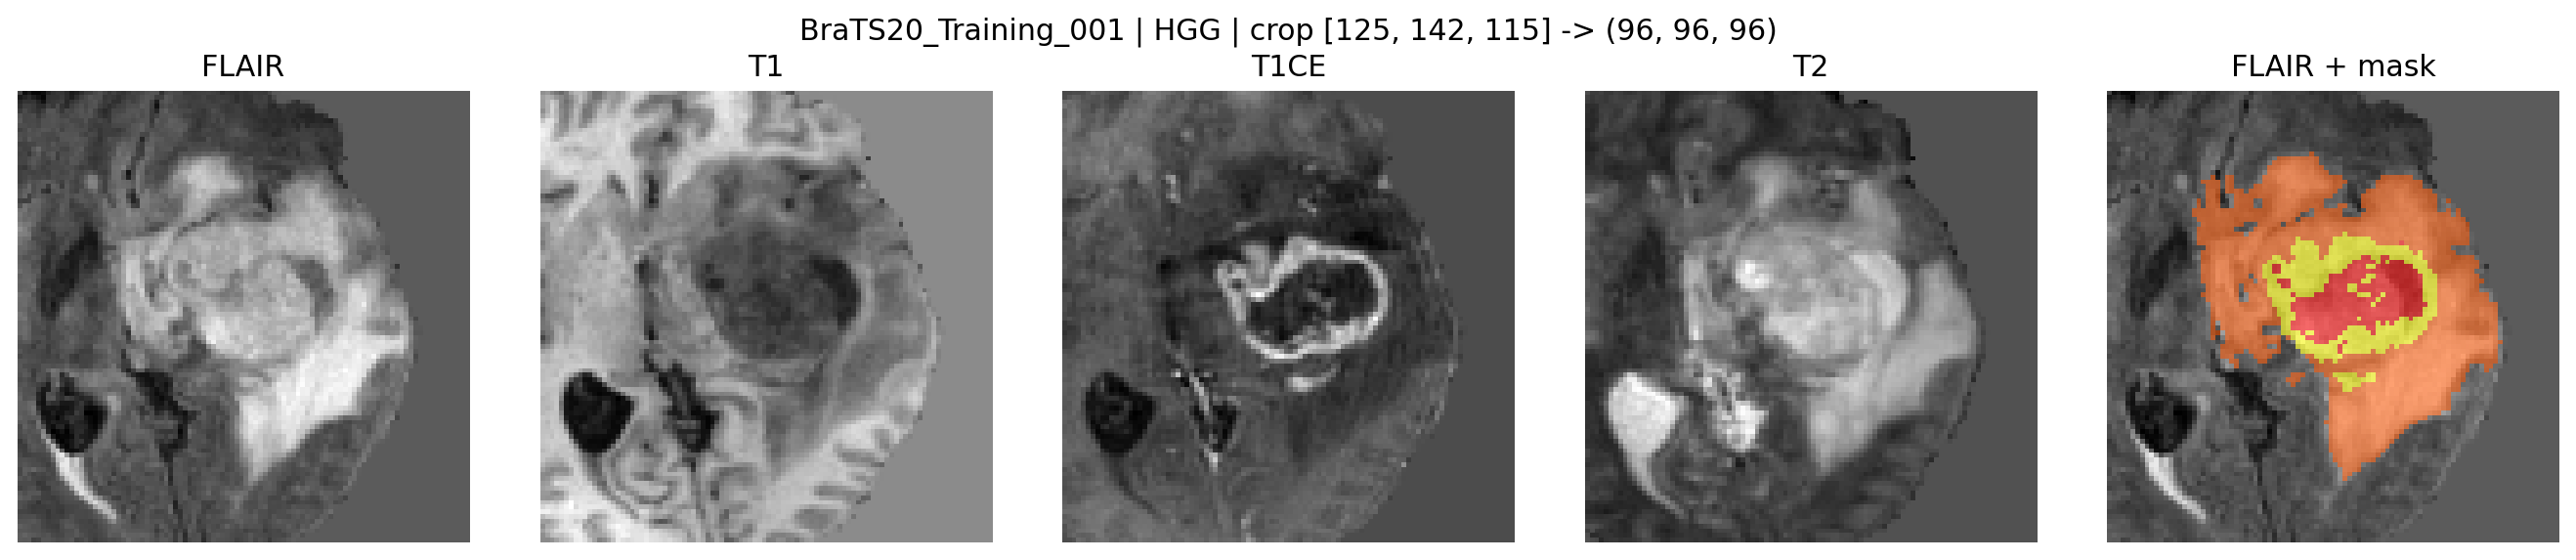

test_BraTS20_Training_005.png


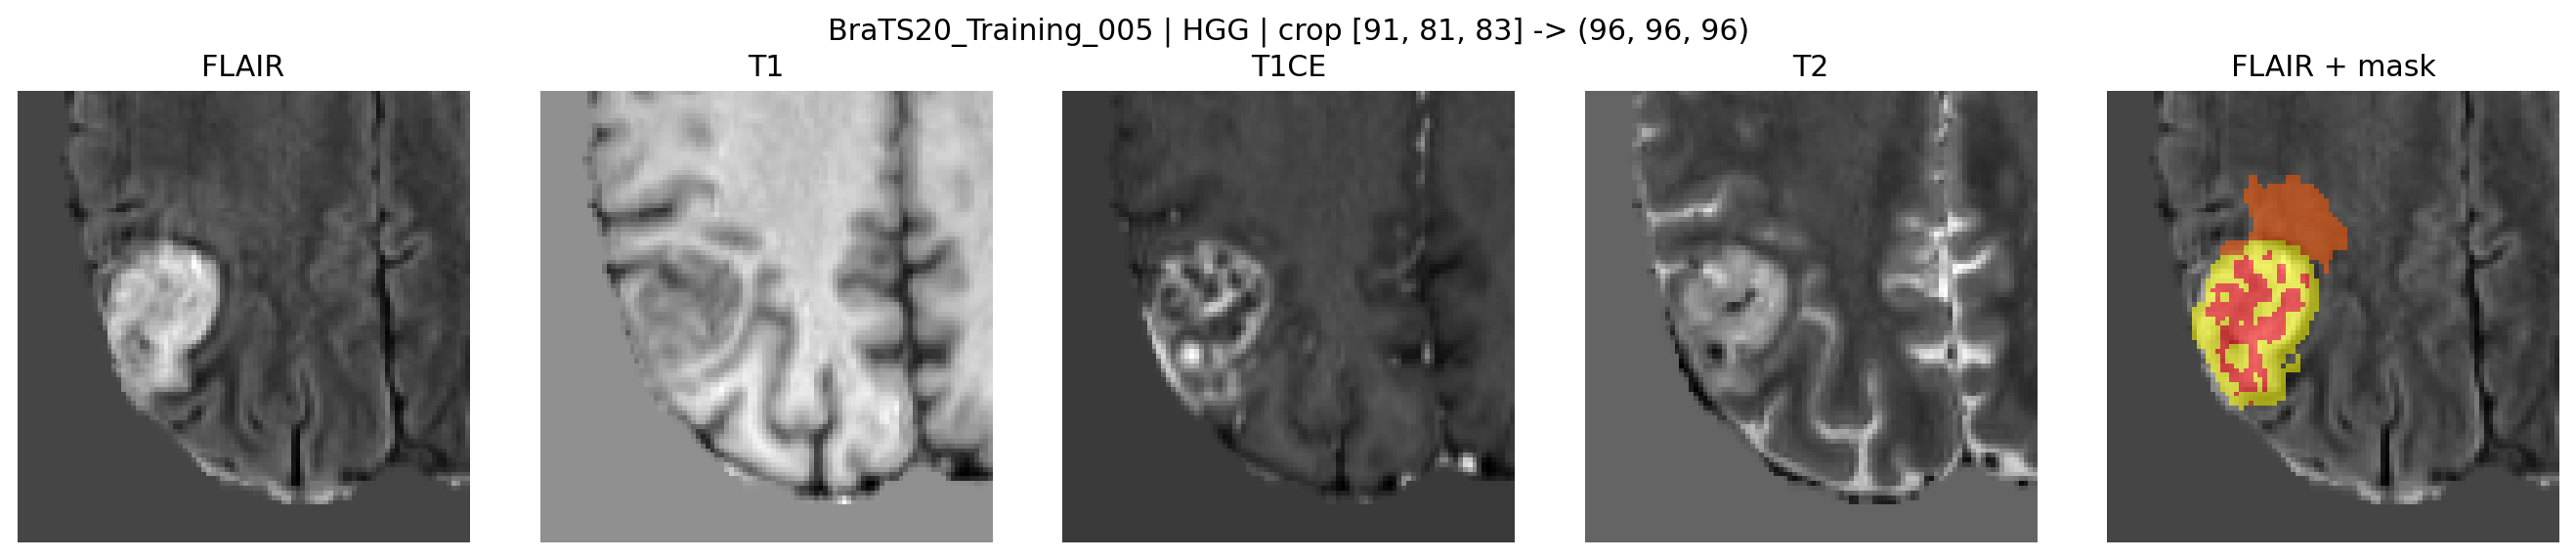

train_BraTS20_Training_002.png


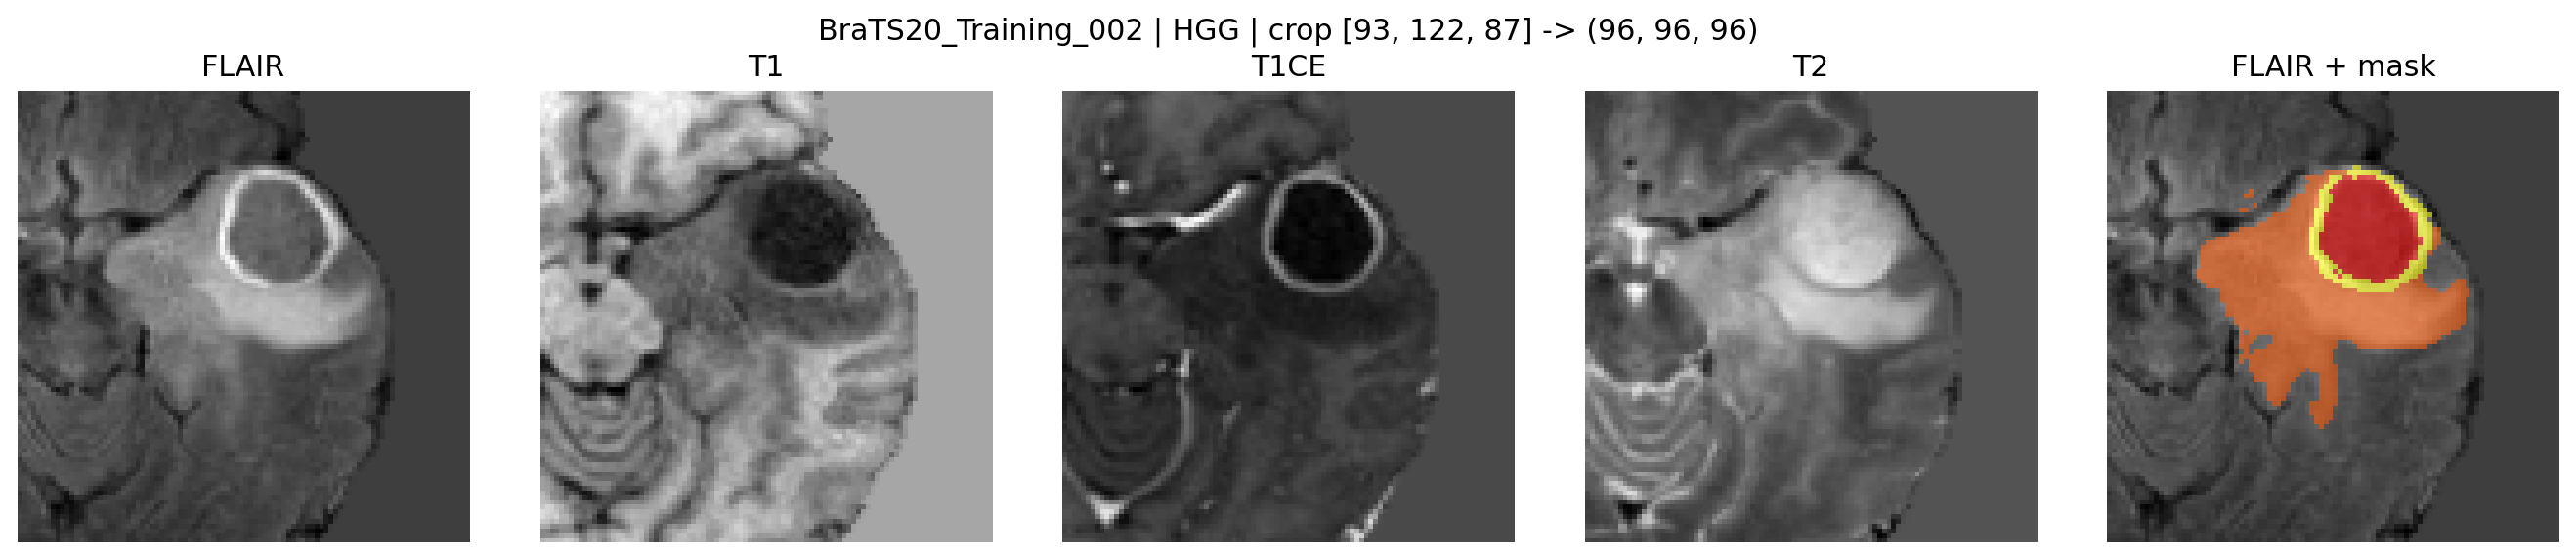

train_BraTS20_Training_003.png


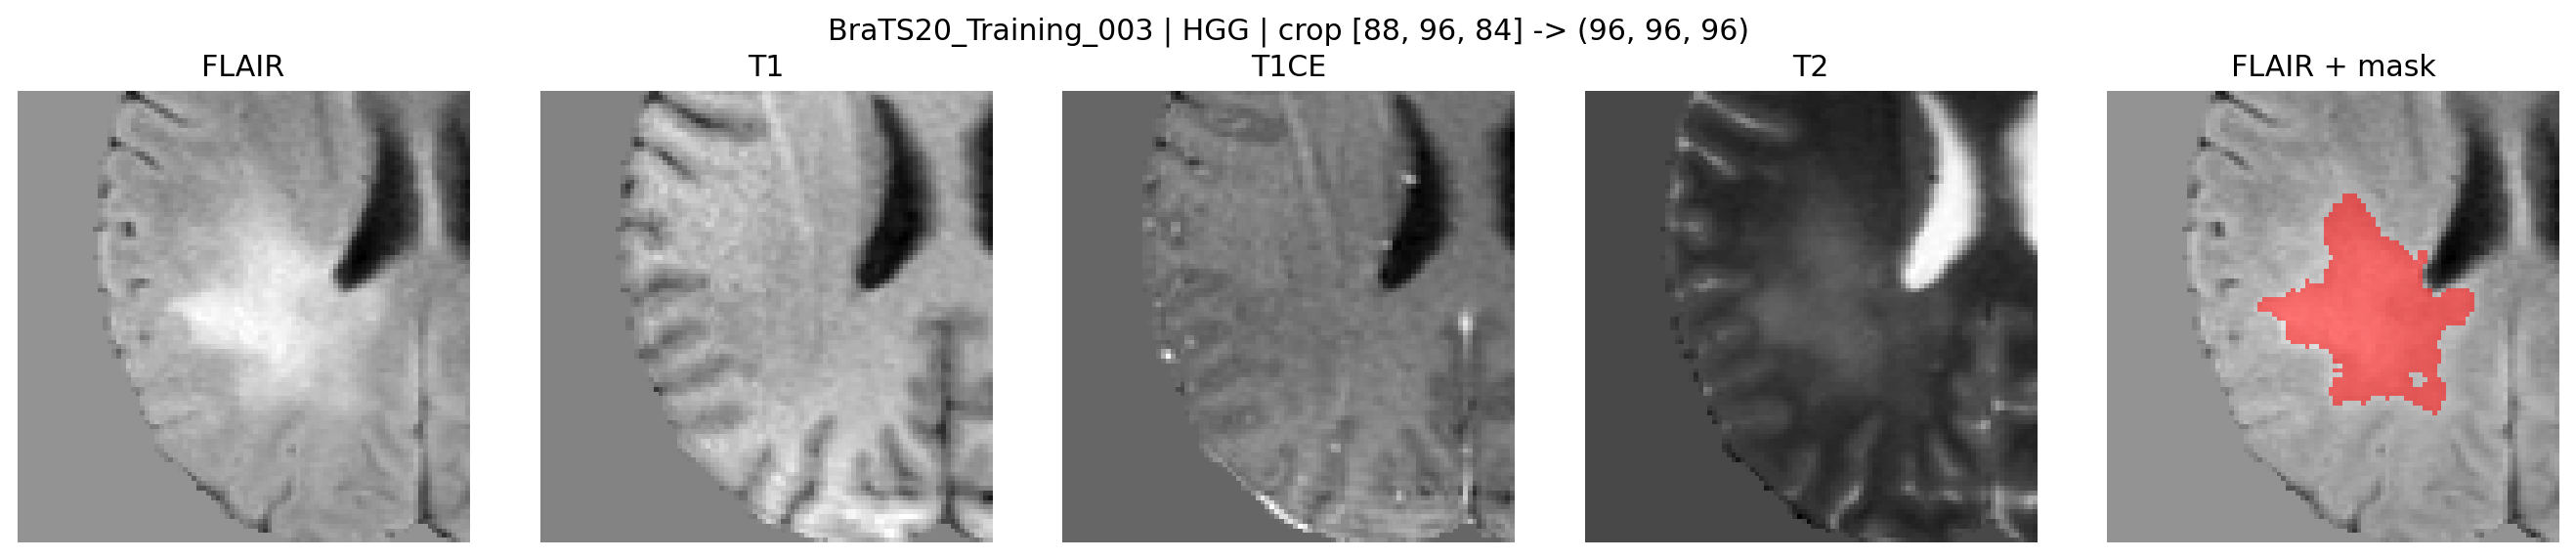

val_BraTS20_Training_004.png


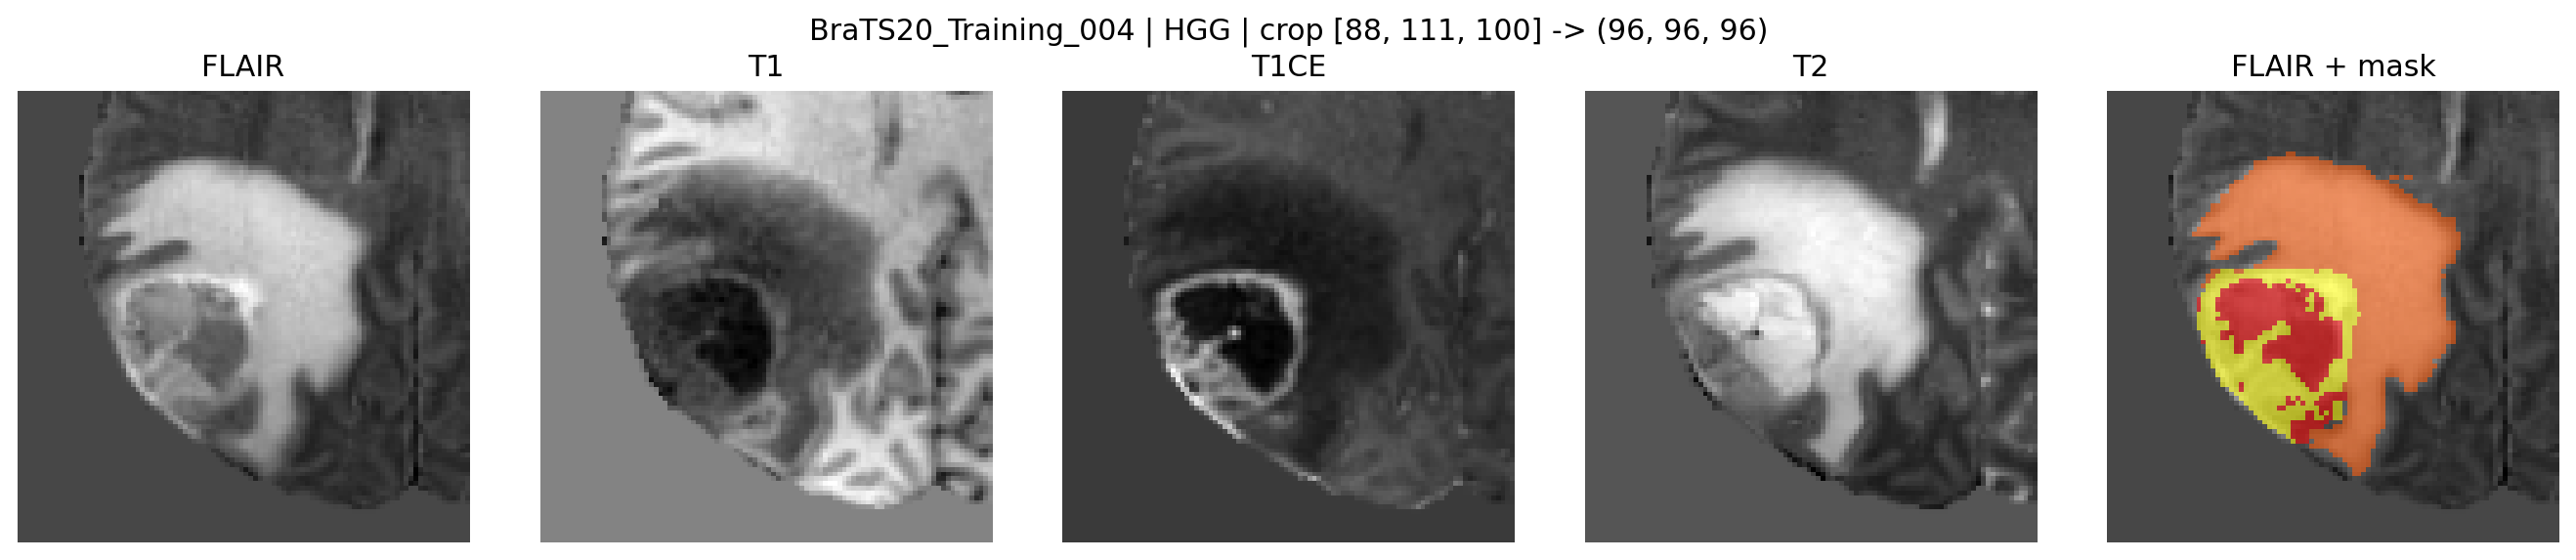

val_BraTS20_Training_007.png


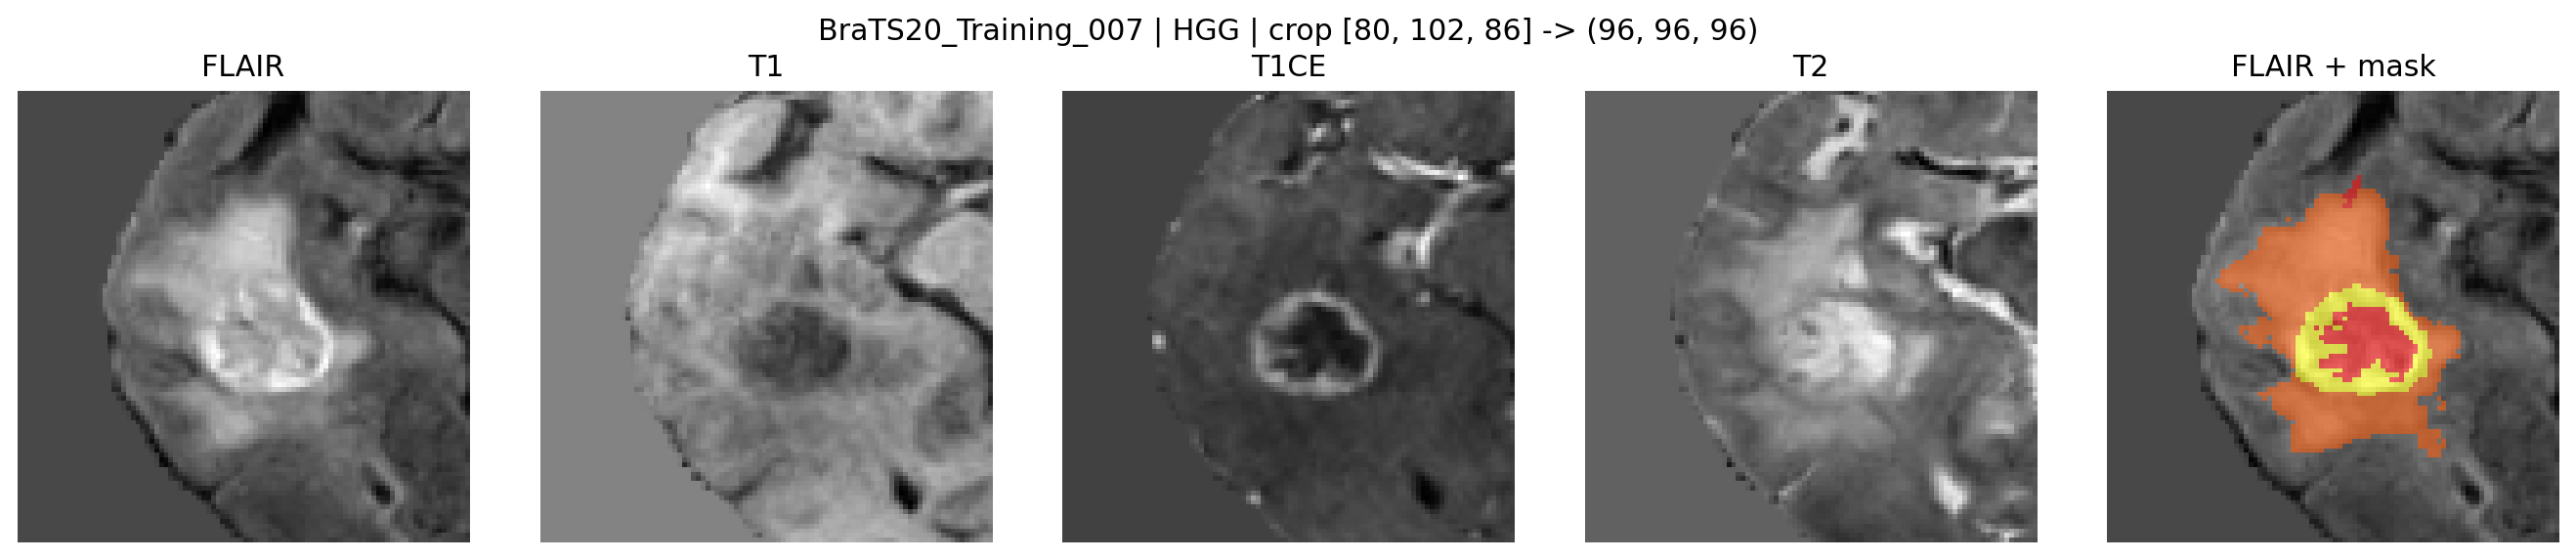

In [10]:
run('-m', 'btp3d.qa', '--manifest', CACHED, '--output-dir', ARTIFACTS / 'qa', '--per-split', 2)
from IPython.display import display
from PIL import Image
for path in sorted((ARTIFACTS / 'qa').glob('*.png')):
    print(path.name)
    display(Image.open(path))


## 8. Check learning on training patients only
The eight-patient check is for debugging. It uses width 4 with dropout disabled and is not the main experiment or a performance result. Expected: 100% training accuracy, loss below 0.02 and matching predictions after checkpoint reload.

In [11]:
DEBUG_MANIFEST = ARTIFACTS / 'training_only_debug_manifest.csv'
cached.loc[cached.split == 'train'].to_csv(DEBUG_MANIFEST, index=False)
run('-m', 'btp3d.overfit_check', '--manifest', DEBUG_MANIFEST,
    '--output-dir', ARTIFACTS / 'overfit_check', '--samples-per-class', 4,
    '--epochs', 200, '--base-channels', 4, '--seed', 42)
debug_result = json.loads((ARTIFACTS / 'overfit_check' / 'overfit_check.json').read_text())
assert debug_result['passed']
print(json.dumps(debug_result, indent=2))


{
  "passed": true,
  "n_patients": 8,
  "epochs": 47,
  "final_loss": 0.019940953701734543,
  "training_accuracy": 1.0,
  "checkpoint_reload_predictions_match": true,
  "patient_ids": [
    "BraTS20_Training_292",
    "BraTS20_Training_323",
    "BraTS20_Training_329",
    "BraTS20_Training_282",
    "BraTS20_Training_025",
    "BraTS20_Training_016",
    "BraTS20_Training_166",
    "BraTS20_Training_113"
  ],
  "warning": "Memorization check only; these are not evaluation metrics."
}
{
  "checkpoint_reload_predictions_match": true,
  "epochs": 47,
  "final_loss": 0.019940953701734543,
  "n_patients": 8,
  "passed": true,
  "patient_ids": [
    "BraTS20_Training_292",
    "BraTS20_Training_323",
    "BraTS20_Training_329",
    "BraTS20_Training_282",
    "BraTS20_Training_025",
    "BraTS20_Training_016",
    "BraTS20_Training_166",
    "BraTS20_Training_113"
  ],
  "training_accuracy": 1.0,
  "warning": "Memorization check only; these are not evaluation metrics."
}


## 9. Train the main GPU model
This is the required main experiment: width 16, input 96-cubed, physical batch 1, accumulation 4, maximum 60 epochs, early-stopping patience 12. Checkpoints are selected by validation balanced accuracy. The script evaluates the held-out test set after training and saves plots and predictions.

Do not select hyperparameters by repeatedly examining the test scores. Keep this cell running until completion. The current trainer saves the best model but does **not** resume optimizer/scheduler state after a disconnect; rerunning starts training again. A disconnected run may have a checkpoint but no completed evaluation.

If CUDA runs out of memory, first restart the runtime and rerun setup while retaining these settings. If a smaller width is necessary, use a separate run directory, document the changed configuration, and do not label it width 16.

In [12]:
assert torch.cuda.is_available(), 'GPU must be enabled.'
TRAIN_ARGS = ['--seed', 42, '--epochs', 60, '--batch-size', 1,
              '--gradient-accumulation', 4, '--learning-rate', 0.0002,
              '--weight-decay', 0.0001, '--patience', 12,
              '--num-workers', 2, '--base-channels', 16,
              '--group-norm-groups', 8, '--dropout', 0.30]
run('-m', 'btp3d.train', '--manifest', CACHED, '--output-dir', RUN, *TRAIN_ARGS)


epoch=001 train_loss=0.5348 val_loss=0.4955 val_bal_acc=0.5000 val_auc=0.5747
epoch=002 train_loss=0.5166 val_loss=0.5013 val_bal_acc=0.5000 val_auc=0.7778
epoch=003 train_loss=0.5125 val_loss=0.4618 val_bal_acc=0.5000 val_auc=0.8283
epoch=004 train_loss=0.4094 val_loss=0.4158 val_bal_acc=0.7859 val_auc=0.8303
epoch=005 train_loss=0.4340 val_loss=0.5642 val_bal_acc=0.5000 val_auc=0.6556
epoch=006 train_loss=0.3410 val_loss=0.5412 val_bal_acc=0.7768 val_auc=0.8788
epoch=007 train_loss=0.2806 val_loss=0.4628 val_bal_acc=0.6818 val_auc=0.7687
epoch=008 train_loss=0.2651 val_loss=0.4866 val_bal_acc=0.6364 val_auc=0.8222
epoch=009 train_loss=0.3233 val_loss=0.3050 val_bal_acc=0.8414 val_auc=0.8737
epoch=010 train_loss=0.1896 val_loss=0.2991 val_bal_acc=0.8758 val_auc=0.9253
epoch=011 train_loss=0.2035 val_loss=0.4304 val_bal_acc=0.7505 val_auc=0.8939
epoch=012 train_loss=0.2670 val_loss=0.3545 val_bal_acc=0.8303 val_auc=0.8970
epoch=013 train_loss=0.1749 val_loss=0.4367 val_bal_acc=0.7626 v

## 10. Read results and demonstrate held-out-patient inference
The chosen patient comes from the fixed test split. This is a repeat inference demonstration, not an independent external validation sample. ROI inference requires a segmentation mask.

{
  "accuracy": 0.8392857142857143,
  "balanced_accuracy": 0.7159090909090908,
  "best_epoch": 10,
  "best_validation_balanced_accuracy": 0.8757575757575757,
  "class_weights_lgg_hgg": [
    2.4245283603668213,
    0.6299019455909729
  ],
  "confusion_matrix_lgg_hgg": [
    [
      6,
      6
    ],
    [
      3,
      41
    ]
  ],
  "device": "cuda",
  "elapsed_seconds": 581.6407113075256,
  "macro_f1": 0.7362637362637363,
  "n_patients": 56,
  "per_class": {
    "HGG": {
      "f1": 0.9010989010989011,
      "precision": 0.8723404255319149,
      "recall": 0.9318181818181818,
      "support": 44
    },
    "LGG": {
      "f1": 0.5714285714285714,
      "precision": 0.6666666666666666,
      "recall": 0.5,
      "support": 12
    }
  },
  "roc_auc": 0.809659090909091,
  "seed": 42,
  "sensitivity_hgg": 0.9318181818181818,
  "specificity_lgg": 0.5,
  "split_counts": {
    "test": {
      "HGG": 44,
      "LGG": 12
    },
    "train": {
      "HGG": 204,
      "LGG": 53
    },
    "va

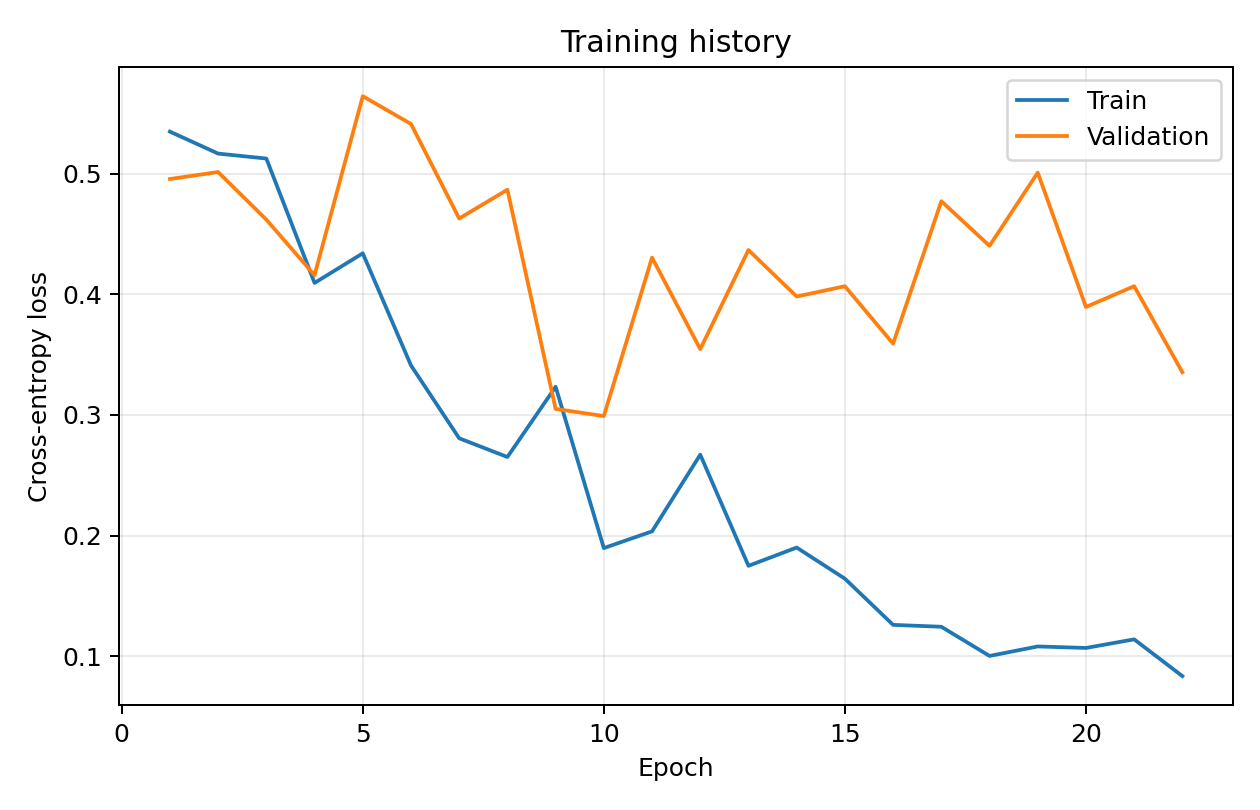

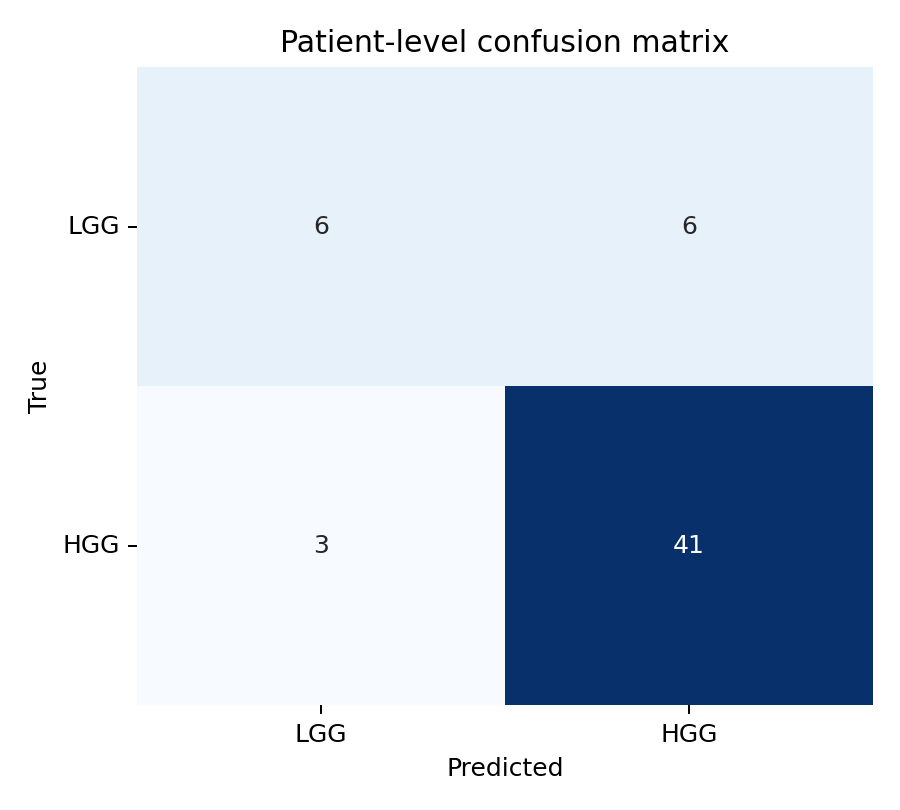

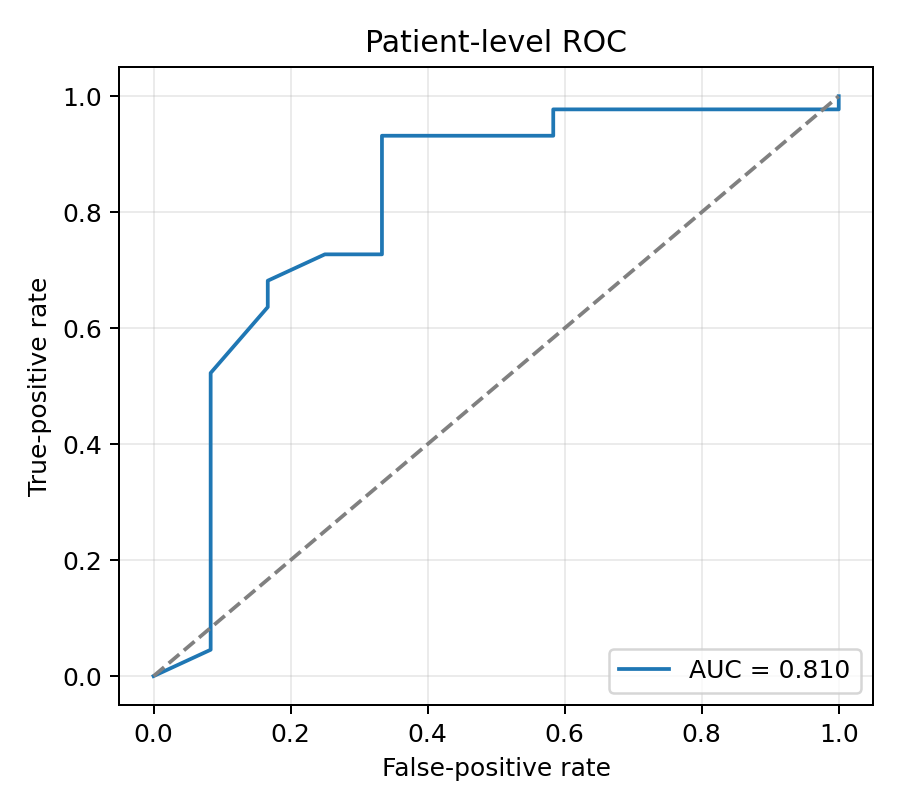

{
  "prediction": "HGG",
  "probability_lgg": 0.016140291467308998,
  "probability_hgg": 0.983859658241272,
  "checkpoint": "/content/drive/MyDrive/BTP1_GPU/runs/roi96_seed42/fixed_split/best_model.pt",
  "preprocessing": {
    "preprocess_config": {
      "spatial_size": [
        96,
        96,
        96
      ],
      "crop_mode": "roi",
      "margin": 16,
      "canonical_orientation": true
    },
    "original_shape": [
      240,
      240,
      155
    ],
    "original_spacing": [
      1.0,
      1.0,
      1.0
    ],
    "orientation": [
      "R",
      "A",
      "S"
    ],
    "crop_bounds": [
      [
        80,
        205
      ],
      [
        37,
        179
      ],
      [
        14,
        129
      ]
    ],
    "cropped_shape": [
      125,
      142,
      115
    ],
    "normalization": {
      "flair": {
        "mean": 173.00338745117188,
        "std": 64.86593627929688,
        "nonzero_voxels": 1342885
      },
      "t1": {
        "mean": 354.27270

In [13]:
metrics = json.loads((RUN / 'test_metrics.json').read_text())
assert metrics['device'].startswith('cuda') and metrics['n_patients'] == 56
checkpoint = torch.load(RUN / 'best_model.pt', map_location='cpu', weights_only=False)
assert checkpoint['model_config']['base_channels'] == 16
assert checkpoint['preprocess_config']['spatial_size'] == [96, 96, 96]
print(json.dumps(metrics, indent=2))
for name in ['loss_curves.png', 'confusion_matrix.png', 'roc_curve.png']:
    display(Image.open(RUN / name))
patient = manifest.loc[manifest.split == 'test'].iloc[0]
infer_args = []
for modality in ['flair', 't1', 't1ce', 't2', 'seg']:
    infer_args += ['--' + modality, patient[modality]]
run('-m', 'btp3d.infer', '--checkpoint', RUN / 'best_model.pt',
    *infer_args, '--output', RUN / 'example_prediction.json')


## 11. Additional experiment: five-fold GPU evaluation
Run after the main experiment if your GPU session budget permits. This trains five additional models. Each patient is tested once; a separate fold is used for validation. The existing script begins again from fold zero when rerun; it has no automatic fold-resume feature. The checkpoint folders on Drive survive, but an interrupted command may need a deliberate restart plan.

Keep this separate from the 32-cubed CPU cross-validation results.

In [17]:
RUN_CV = True  # Change to True only when ready for five additional training runs.
if RUN_CV:
    assert torch.cuda.is_available()
    run('-m', 'btp3d.cross_validate', '--manifest', CACHED,
        '--output-dir', ARTIFACTS / 'cv5', *TRAIN_ARGS)
    print((ARTIFACTS / 'cv5' / 'cross_validation_metrics.json').read_text())


epoch=001 train_loss=0.5561 val_loss=0.5107 val_bal_acc=0.5000 val_auc=0.5203
epoch=002 train_loss=0.5332 val_loss=0.5120 val_bal_acc=0.5000 val_auc=0.6927
epoch=003 train_loss=0.5162 val_loss=0.5071 val_bal_acc=0.5000 val_auc=0.7565
epoch=004 train_loss=0.5279 val_loss=0.4959 val_bal_acc=0.5000 val_auc=0.8113
epoch=005 train_loss=0.5148 val_loss=0.4820 val_bal_acc=0.5000 val_auc=0.8503
epoch=006 train_loss=0.5214 val_loss=0.5114 val_bal_acc=0.5000 val_auc=0.4915
epoch=007 train_loss=0.5048 val_loss=0.4884 val_bal_acc=0.5000 val_auc=0.8966
epoch=008 train_loss=0.5082 val_loss=0.4766 val_bal_acc=0.5000 val_auc=0.7661
epoch=009 train_loss=0.4640 val_loss=0.3760 val_bal_acc=0.5000 val_auc=0.8983
epoch=010 train_loss=0.4041 val_loss=0.3633 val_bal_acc=0.8565 val_auc=0.9322
epoch=011 train_loss=0.2982 val_loss=0.2355 val_bal_acc=0.8328 val_auc=0.9627
epoch=012 train_loss=0.2540 val_loss=0.3339 val_bal_acc=0.8322 val_auc=0.9390
epoch=013 train_loss=0.2012 val_loss=0.2920 val_bal_acc=0.7915 v

## 12. Additional experiment: whole-brain comparison
Uses the same patient splits and training settings. Brain cropping does not use the tumour mask. Compare its fixed-split results with the ROI fixed-split results; do not compare different evaluation schemes as if they were identical.

In [18]:
RUN_WHOLE_BRAIN = True  # Change to True when ready for one additional model.
if RUN_WHOLE_BRAIN:
    BRAIN_CACHE = Path('/content/brain96_cache')
    run('-m', 'btp3d.preprocess', '--manifest', MANIFEST, '--output-dir', BRAIN_CACHE,
        '--spatial-size', 96, 96, 96, '--crop-mode', 'brain', '--margin', 0, '--workers', 2)
    run('-m', 'btp3d.train', '--manifest', BRAIN_CACHE / 'manifest_cached.csv',
        '--output-dir', ARTIFACTS / 'whole_brain_fixed', *TRAIN_ARGS)



Preprocessing patients: 100%|██████████| 369/369 [07:24<00:00,  1.20s/it]
Cached 369 patients at /content/brain96_cache
epoch=001 train_loss=0.5308 val_loss=0.4947 val_bal_acc=0.5000 val_auc=0.7152
epoch=002 train_loss=0.5164 val_loss=0.5012 val_bal_acc=0.5000 val_auc=0.7515
epoch=003 train_loss=0.5142 val_loss=0.4611 val_bal_acc=0.5000 val_auc=0.7980
epoch=004 train_loss=0.4801 val_loss=0.4867 val_bal_acc=0.5000 val_auc=0.7566
epoch=005 train_loss=0.4659 val_loss=0.4931 val_bal_acc=0.5000 val_auc=0.8333
epoch=006 train_loss=0.3940 val_loss=0.4102 val_bal_acc=0.7970 val_auc=0.7677
epoch=007 train_loss=0.3468 val_loss=0.4305 val_bal_acc=0.6596 val_auc=0.8566
epoch=008 train_loss=0.3357 val_loss=0.3781 val_bal_acc=0.7162 val_auc=0.8687
epoch=009 train_loss=0.2794 val_loss=0.3369 val_bal_acc=0.7273 val_auc=0.8717
epoch=010 train_loss=0.3176 val_loss=0.4241 val_bal_acc=0.6707 val_auc=0.8364
epoch=011 train_loss=0.2236 val_loss=0.4111 val_bal_acc=0.6374 val_auc=0.8354
epoch=012 train_loss=

## 13. Verify and save the completed run
Keep the notebook with its executed outputs. Drive already contains the saved results; this cell also creates a download ZIP. It excludes raw MRI and caches.

If the runtime resets: remount Drive, reinstall code, obtain the data again and rebuild `/content` caches before starting a new training command. Saved manifests contain runtime paths and cannot alone restore deleted cached tensors.

Training time depends on the assigned GPU and runtime limits. Measure the first run rather than assuming an exact duration. Five-fold evaluation requires five additional model fits; whole-brain comparison requires one more.

In [20]:
required = ['best_model.pt', 'history.csv', 'test_predictions.csv', 'test_metrics.json',
            'loss_curves.png', 'confusion_matrix.png', 'roc_curve.png']
assert all((RUN / name).is_file() for name in required), 'Main experiment is incomplete.'
print('Completed main run:', RUN)
archive = shutil.make_archive('/content/BTP1_GPU_Results', 'zip', ARTIFACTS)
from google.colab import files
files.download(archive)


Completed main run: /content/drive/MyDrive/BTP1_GPU/runs/roi96_seed42/fixed_split


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>